# AI 2 · Deep Learning: a neural network in PyTorch
**We train it ourselves:** a small network of neurons. It learns with **gradient descent**:
predict → measure error (loss) → compute gradients → nudge the weights a little → repeat.

**The task (the same in all four notebooks):** predict tomorrow's Apple (AAPL) closing price.
We test on the **last 60 trading days**, and the model never sees them during training.

**Baseline to beat:** "tomorrow = today". If a model cannot beat this, it has learned nothing useful.

In [1]:
import pandas as pd

prices = pd.read_parquet("../lecture03_datascience/sample/prices_sample.parquet")
aapl = prices[prices["symbol"] == "AAPL"].set_index("date")["close"]
aapl.tail()

date
2025-02-10    227.65
2025-02-11    232.62
2025-02-12    236.87
2025-02-13    241.53
2025-02-14    244.60
Name: close, dtype: float64

## Features: exactly the same as for the Random Forest

In [2]:
# Daily return in percent: +1.0 means the price rose by 1 % since yesterday
ret = aapl.pct_change() * 100

# Input X: the returns of the last 10 days (lag0 = today, lag9 = 9 days ago)
X = pd.concat({f"lag{i}": ret.shift(i) for i in range(10)}, axis=1)

# Target y: tomorrow's return
y = ret.shift(-1).rename("target")

data = pd.concat([X, y], axis=1).dropna()
data.tail(3).round(2)

,lag0,lag1,lag2,lag3,lag4,lag5,lag6,lag7,lag8,lag9,target
date,,,,,,,,,,,
2025-02-11,2.18,0.12,-2.40,0.32,-0.14,2.10,-3.39,-0.67,-0.74,0.46,1.83
2025-02-12,1.83,2.18,0.12,-2.40,0.32,-0.14,2.10,-3.39,-0.67,-0.74,1.97
2025-02-13,1.97,1.83,2.18,0.12,-2.40,0.32,-0.14,2.10,-3.39,-0.67,1.27


## Train / test split
The same `train_test_split` as for Auto MPG, with one important difference: **`shuffle=False`**.
Time series must not be shuffled. Otherwise the model trains on days *after* the test days and peeks into the future.
```
shuffle=True  (Auto MPG):  train test train train test train ...   random rows
shuffle=False (stocks)  :  train train train ... train | test test  last 60 days
```

In [3]:
from sklearn.model_selection import train_test_split

train, test = train_test_split(data, test_size=60, shuffle=False)
print("train:", train.index.min().date(), "to", train.index.max().date(), f"({len(train)} days)")
print("test :", test.index.min().date(), "to", test.index.max().date(), f"({len(test)} days)")

train: 2020-03-03 to 2024-11-14 (1186 days)
test : 2024-11-15 to 2025-02-13 (60 days)


## Data as tensors (PyTorch's arrays)

In [4]:
import torch

torch.manual_seed(42)
X_train = torch.tensor(train.drop(columns="target").values, dtype=torch.float32)
y_train = torch.tensor(train[["target"]].values, dtype=torch.float32)
X_test = torch.tensor(test.drop(columns="target").values, dtype=torch.float32)
X_train.shape   # (days, 10 features)

torch.Size([1186, 10])

## The network: 10 inputs → 32 neurons → 1 output
```
lag0..lag9  ──►  [32 neurons, ReLU]  ──►  tomorrow's return
```

In [10]:
from torch import nn

net = nn.Sequential(
    nn.Linear(10, 32),   # 10*32 weights + 32 biases
    nn.ReLU(),           # max(0, z): makes the network non-linear
    nn.Linear(32, 1),    # 32 weights + 1 bias
)
sum(p.numel() for p in net.parameters())   # number of trainable parameters

385

## Training loop: 300 steps of gradient descent

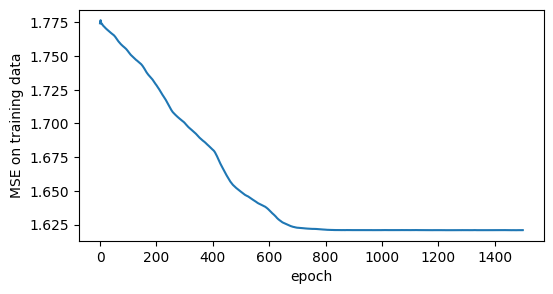

In [12]:
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(net.parameters(), lr=0.001)

losses = []
for epoch in range(1500):

    optimizer.zero_grad()                       # forget old gradients
    loss = loss_fn(net(X_train), y_train)       # 1. predict + 2. measure error
    loss.backward()                             # 3. gradients (chain rule)
    optimizer.step()                            # 4. update weights
    losses.append(loss.item())

pd.Series(losses).plot(xlabel="epoch", ylabel="MSE on training data", figsize=(6, 3));

## Predict the 60 test days

In [13]:
with torch.no_grad():                           # no training, so no gradients needed
    pred = net(X_test).squeeze().numpy()
MODEL_NAME = "Neural network"
pred[:5].round(3)

array([ 0.599, -1.397,  1.105,  1.055,  1.255], dtype=float32)

## Evaluate

In [14]:
from sklearn.metrics import mean_absolute_error

today = aapl.loc[test.index]                      # today's price
true_price = aapl.shift(-1).loc[test.index]       # tomorrow's price (the truth)
model_price = today * (1 + pred / 100)            # return -> price

print(f"MAE baseline 'tomorrow = today': {mean_absolute_error(true_price, today):.2f} $")
print(f"MAE {MODEL_NAME:<27}: {mean_absolute_error(true_price, model_price):.2f} $")

MAE baseline 'tomorrow = today': 2.68 $
MAE Neural network             : 3.31 $


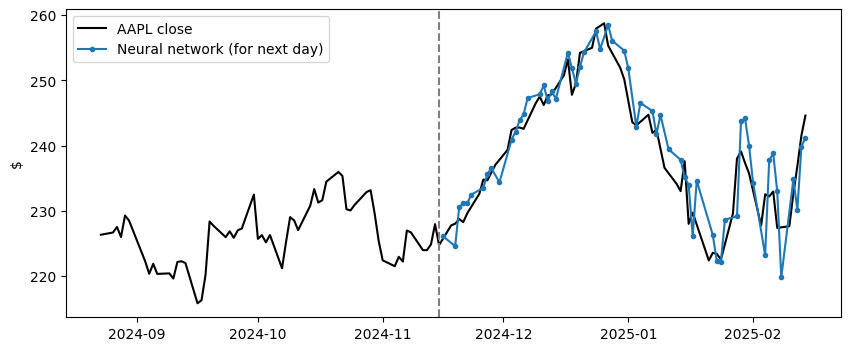

In [15]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(aapl.iloc[-120:], color="black", label="AAPL close")
ax.plot(test.index + pd.Timedelta(days=1), model_price, "o-", ms=3, label=MODEL_NAME + " (for next day)")
ax.axvline(test.index[0], color="gray", ls="--")
ax.set_ylabel("$")
ax.legend();

## Would we have made money?
Simple rule with **1 share**: if the model says "up", buy today at the close and sell tomorrow at the close.
If it says "down", do nothing. Compare with **buy & hold**: buy once and keep the share for all 60 days.

In [16]:
import numpy as np

def trading_days(today, tomorrow, pred):
    days = pd.DataFrame({"today $": today.values, "tomorrow $": tomorrow.values}, index=today.index)
    days["model says"] = np.where(pred > 0, "up -> buy", "down -> wait")
    days["profit $"] = np.where(pred > 0, days["tomorrow $"] - days["today $"], 0.0)
    days["running total $"] = days["profit $"].cumsum()
    return days.round(2)


def trading_summary(days):
    bought = days[days["model says"] == "up -> buy"]
    return pd.DataFrame({
        "days bought": [len(bought)],
        "won": [(bought["profit $"] > 0).sum()],
        "lost": [(bought["profit $"] < 0).sum()],
        "model profit $": [days["profit $"].sum()],
        "buy & hold profit $": [(days["tomorrow $"] - days["today $"]).sum()],
    }).round(2)


days = trading_days(today, true_price, pred)
days.head(8)   # the first 8 test days, one row per day

,today $,tomorrow $,model says,profit $,running total $
date,,,,,
2024-11-15,224.75,227.77,up -> buy,3.02,3.02
2024-11-18,227.77,228.03,down -> wait,0.00,3.02
2024-11-19,228.03,228.75,up -> buy,0.72,3.74
2024-11-20,228.75,228.27,up -> buy,-0.48,3.26
2024-11-21,228.27,229.62,up -> buy,1.35,4.61
2024-11-22,229.62,232.61,up -> buy,2.99,7.60
2024-11-25,232.61,234.80,up -> buy,2.19,9.79
2024-11-26,234.80,234.67,up -> buy,-0.13,9.66


In [17]:
trading_summary(days)

,days bought,won,lost,model profit $,buy & hold profit $
0,41,25,16,18.24,19.85


## Check: does the AAPL model also work on other stocks?
If the network had learned a real pattern of "how stocks move", it should also help on Microsoft, Amazon and Google.
We build the same features for each stock and use the **AAPL model unchanged**: only `predict`, **no `fit`**.

The grey line is the baseline "tomorrow = today", i.e. yesterday's price.

In [18]:
def apply_aapl_model(symbol):
    close = prices[prices["symbol"] == symbol].set_index("date")["close"]

    # same features as for AAPL
    r = close.pct_change() * 100
    X_s = pd.concat({f"lag{i}": r.shift(i) for i in range(10)}, axis=1)
    data_s = pd.concat([X_s, r.shift(-1).rename("target")], axis=1).dropna()
    _, test_s = train_test_split(data_s, test_size=60, shuffle=False)   # only the last 60 days, the rest is thrown away

    # NO fit here: the AAPL model is only applied
    pred_s = net(torch.tensor(test_s.drop(columns="target").values, dtype=torch.float32)).detach().squeeze().numpy()
    today_s = close.loc[test_s.index]
    true_s = close.shift(-1).loc[test_s.index]
    model_s = today_s * (1 + pred_s / 100)

    print(f"{symbol:<6} MAE baseline 'tomorrow = today': {mean_absolute_error(true_s, today_s):.2f} $")
    print(f"{symbol:<6} MAE AAPL network               : {mean_absolute_error(true_s, model_s):.2f} $")

    next_day = test_s.index + pd.Timedelta(days=1)
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(close.iloc[-120:], color="black", label=f"{symbol} close")
    ax.plot(next_day, today_s, color="gray", lw=3, alpha=0.6, label="baseline: tomorrow = today")
    ax.plot(next_day, model_s, "o-", ms=3, color="C3", label="AAPL network (for next day)")
    ax.axvline(test_s.index[0], color="gray", ls="--")
    ax.set_title(f"AAPL model applied to {symbol} (never trained on {symbol})")
    ax.set_ylabel("$")
    ax.legend()
    plt.show()
    display(trading_summary(trading_days(today_s, true_s, pred_s)))

MSFT   MAE baseline 'tomorrow = today': 4.25 $
MSFT   MAE AAPL network               : 6.66 $


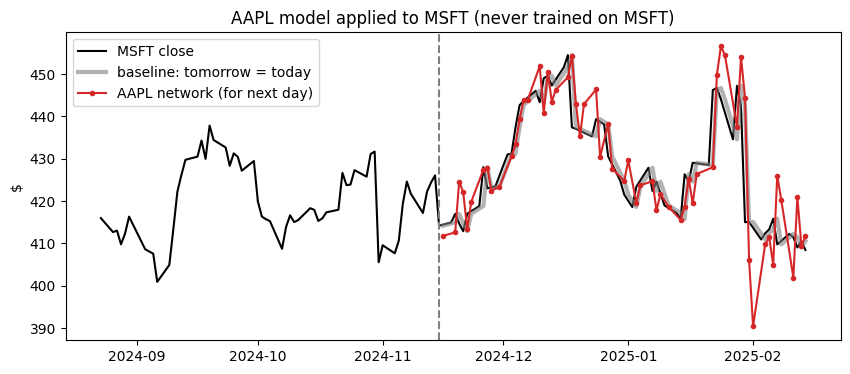

,days bought,won,lost,model profit $,buy & hold profit $
0,30,16,14,-2.31,-5.74


In [19]:
apply_aapl_model("MSFT")

AMZN   MAE baseline 'tomorrow = today': 2.96 $
AMZN   MAE AAPL network               : 3.96 $


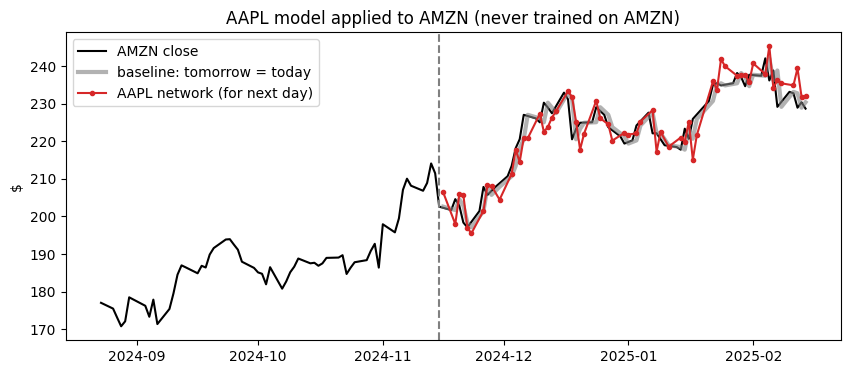

,days bought,won,lost,model profit $,buy & hold profit $
0,38,19,19,17.48,26.07


In [20]:
apply_aapl_model("AMZN")

GOOGL  MAE baseline 'tomorrow = today': 2.97 $
GOOGL  MAE AAPL network               : 4.13 $


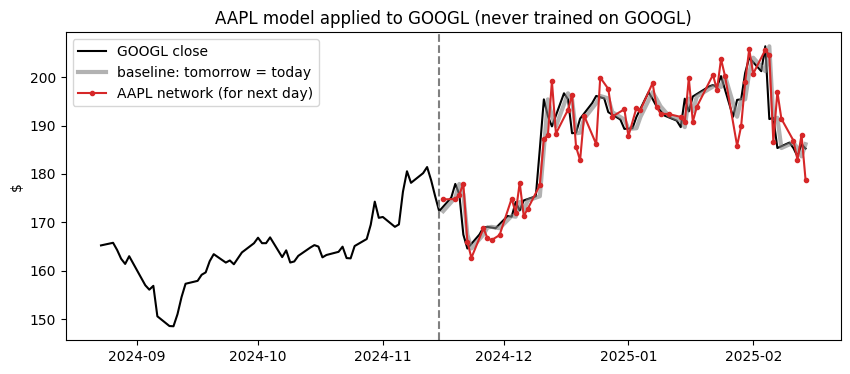

,days bought,won,lost,model profit $,buy & hold profit $
0,31,16,15,16.98,12.94


In [21]:
apply_aapl_model("GOOGL")

**Intel (INTC)** for contrast: a stock that **fell** about 60 % in 5 years. The rule 'model says up → buy' cannot ride an upward trend here.

INTC   MAE baseline 'tomorrow = today': 0.47 $
INTC   MAE AAPL network               : 0.63 $


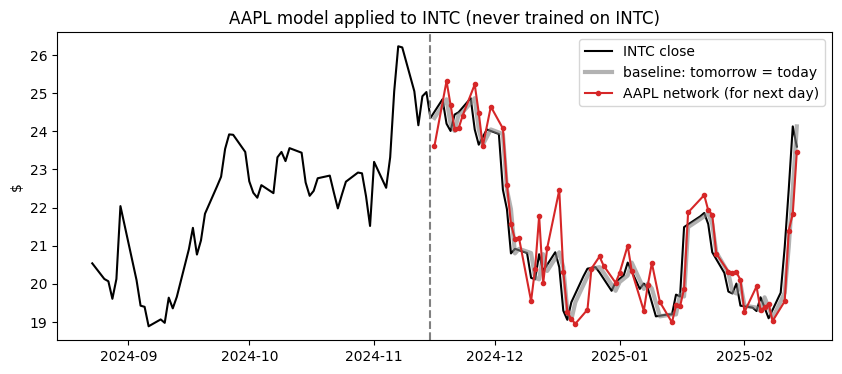

,days bought,won,lost,model profit $,buy & hold profit $
0,37,17,20,-0.72,-0.75


In [22]:
apply_aapl_model("INTC")

## Takeaway
- More code than the Random Forest: **we** write the training loop.
- Results on the same 60 test days, network next to the forest from notebook 1:

| stock | MAE baseline | MAE forest | MAE network | profit forest | profit network | profit buy & hold |
|---|---|---|---|---|---|---|
| AAPL (trained) | 2.68 $ | 2.54 $ | 2.58 $ | +20.52 $ | +16.43 $ | +19.85 $ |
| MSFT | 4.25 $ | 4.49 $ | 4.61 $ | +11.99 $ | +7.91 $ | −5.74 $ |
| AMZN | 2.96 $ | 2.90 $ | 2.96 $ | +24.63 $ | +38.00 $ | +26.07 $ |
| GOOGL | 2.97 $ | 2.74 $ | 2.92 $ | +38.94 $ | +36.46 $ | +12.94 $ |
| INTC | 0.47 $ | 0.51 $ | 0.55 $ | −5.10 $ | −0.49 $ | −0.75 $ |

- By MAE the network is never better than the forest, and on MSFT and INTC it is worse than "tomorrow = today".
- By profit sometimes one wins, sometimes the other. Two models with almost the same MAE make quite different trades: that is noise, not skill.
- A neural network is not automatically better. With 10 numbers per day as input and about 1,200 days of training data, it has nothing more to find than the forest.
- Deep learning shines with **huge data and raw signals** (images, audio, text), not with 1,200 rows.